#Drive Mount + Paths

In [9]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

#Project folder in Drive
BASE = "/content/drive/MyDrive/CourseWork/CSV_Files"

import os
DATA_DIR = BASE
OUT_DIR  = f"{BASE}/Cleaned_Output"
os.makedirs(OUT_DIR, exist_ok=True)

# Input file name
BUSINESS_FILE = "yelp_academic_dataset_checkin.csv"
IN_PATH = f"{DATA_DIR}/{BUSINESS_FILE}"

# Two outputs
OUT_EVENTS_NAME = "Cleaned_checkin_events"             # event grain (timestamp level)
OUT_DAILY_NAME  = "Cleaned_checkin_daily_features"     # daily grain + predictive-ready features

print("IN_PATH:", IN_PATH)
print("OUT_DIR:", OUT_DIR)


Mounted at /content/drive
IN_PATH: /content/drive/MyDrive/CourseWork/CSV_Files/yelp_academic_dataset_checkin.csv
OUT_DIR: /content/drive/MyDrive/CourseWork/CSV_Files/Cleaned_Output


#Environmental Setup + Spark Session

In [2]:
!pip -q install pyspark

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

spark = (SparkSession.builder
         .appName("Checkin_Footfall_Descriptive_Cleaning")
         .getOrCreate())

spark.sparkContext.setLogLevel("WARN")
print("Spark ready:", spark.version)


Spark ready: 4.0.1


#Data Loading

In [3]:
df_C1 = (spark.read
         .option("header", True)
         .option("inferSchema", True)
         .csv(IN_PATH))

df_C1.printSchema()
df_C1.show(5, truncate=False)
print("Rows:", df_C1.count(), "| Cols:", len(df_C1.columns))


root
 |-- business_id: string (nullable = true)
 |-- date: string (nullable = true)

+----------------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|business_id           |date                                                                                                                                                                                                                                                                                                                             

#Data Cleaning

##Cleaning + Standarization

In [4]:
df_C2 = df_C1.select("business_id", "date").dropna(subset=["business_id", "date"])

df_C2 = (df_C2
         .withColumn("business_id", F.trim(F.col("business_id").cast("string")))
         .withColumn("date", F.col("date").cast("string"))
         .withColumn("date", F.regexp_replace("date", r"\s+", " "))
         .withColumn("date", F.regexp_replace("date", r"\s*,\s*", ","))  # normalize commas
         .withColumn("date", F.regexp_replace("date", r"^,+|,+$", ""))   # strip leading/trailing commas
         .filter(F.length("date") > 0))

df_C2.show(5, truncate=False)


+----------------------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|business_id           |date                                                                                                                                                                                                                                                                                                                                                                                                                                           

##Feature Extraction

In [5]:
# Explode comma-separated timestamps → one row per check-in timestamp
df_C3 = (df_C2
         .withColumn("checkin_str", F.explode(F.split(F.col("date"), ",")))
         .withColumn("checkin_str", F.trim(F.col("checkin_str")))
         .filter(F.length("checkin_str") > 0))

# Parse timestamp
df_C3 = df_C3.withColumn("checkin_ts", F.to_timestamp("checkin_str", "yyyy-MM-dd HH:mm:ss"))

# Drop un-parseable timestamps
df_C3 = df_C3.dropna(subset=["checkin_ts"])

# Event-level time features (needed for heatmap + weekend share)
df_C3 = (df_C3
         .withColumn("checkin_date", F.to_date("checkin_ts"))
         .withColumn("hour", F.hour("checkin_ts"))
         .withColumn("dow",  F.dayofweek("checkin_ts"))  # 1=Sun..7=Sat
         .withColumn("is_weekend", F.when(F.col("dow").isin([1,7]), 1).otherwise(0)))

df_C3.select("business_id","checkin_ts","checkin_date","hour","dow","is_weekend").show(5, truncate=False)
print("Event rows:", df_C3.count())


+----------------------+-------------------+------------+----+---+----------+
|business_id           |checkin_ts         |checkin_date|hour|dow|is_weekend|
+----------------------+-------------------+------------+----+---+----------+
|---kPU91CF4Lq2-WlRu9Lw|2020-03-13 21:10:56|2020-03-13  |21  |6  |0         |
|---kPU91CF4Lq2-WlRu9Lw|2020-06-02 22:18:06|2020-06-02  |22  |3  |0         |
|---kPU91CF4Lq2-WlRu9Lw|2020-07-24 22:42:27|2020-07-24  |22  |6  |0         |
|---kPU91CF4Lq2-WlRu9Lw|2020-10-24 21:36:13|2020-10-24  |21  |7  |1         |
|---kPU91CF4Lq2-WlRu9Lw|2020-12-09 21:23:33|2020-12-09  |21  |4  |0         |
+----------------------+-------------------+------------+----+---+----------+
only showing top 5 rows
Event rows: 13356875


##Aggregations + Other Features

In [6]:
# Daily aggregation (target series)
df_C4_daily = (df_C3
    .groupBy("checkin_date")
    .agg(F.count("*").alias("checkins"))
    .orderBy("checkin_date")
)

# Calendar features
df_C4_daily = (df_C4_daily
    .withColumn("day_of_week", F.dayofweek("checkin_date"))  # 1=Sun..7=Sat
    .withColumn("month", F.month("checkin_date"))
    .withColumn("year", F.year("checkin_date"))
    .withColumn("is_weekend", F.when(F.col("day_of_week").isin([1,7]), 1).otherwise(0))
)

# Lag & rolling features (used later in predictive analysis)
w_order = Window.orderBy(F.col("checkin_date").cast("timestamp"))
w7 = w_order.rowsBetween(-6, 0)

df_C5_daily_feat = (df_C4_daily
    .withColumn("checkins_7d_avg", F.round(F.avg("checkins").over(w7), 2))
    .withColumn("lag_1", F.lag("checkins", 1).over(w_order))
    .withColumn("lag_7", F.lag("checkins", 7).over(w_order))
    .withColumn("rolling_mean_7", F.round(F.avg("checkins").over(w7), 2))
)

# High-traffic label
p75 = df_C5_daily_feat.approxQuantile("checkins", [0.75], 0.01)[0]
print("Overall 75th percentile threshold (for label column only):", p75)

df_C5_daily_feat = df_C5_daily_feat.withColumn(
    "high_traffic",
    F.when(F.col("checkins") > F.lit(p75), 1).otherwise(0)
)

df_C5_daily_feat.show(10, truncate=False)


Overall 75th percentile threshold (for label column only): 3951.0
+------------+--------+-----------+-----+----+----------+---------------+-----+-----+--------------+------------+
|checkin_date|checkins|day_of_week|month|year|is_weekend|checkins_7d_avg|lag_1|lag_7|rolling_mean_7|high_traffic|
+------------+--------+-----------+-----+----+----------+---------------+-----+-----+--------------+------------+
|2009-12-30  |1       |4          |12   |2009|0         |1.0            |NULL |NULL |1.0           |0           |
|2009-12-31  |1       |5          |12   |2009|0         |1.0            |1    |NULL |1.0           |0           |
|2010-01-16  |100     |7          |1    |2010|1         |34.0           |1    |NULL |34.0          |0           |
|2010-01-17  |135     |1          |1    |2010|1         |59.25          |100  |NULL |59.25         |0           |
|2010-01-18  |69      |2          |1    |2010|0         |61.2           |135  |NULL |61.2          |0           |
|2010-01-19  |58      

#Saving Cleaned Dataset

In [10]:
import glob, shutil

def save_single_csv(df_in, out_dir, base_name, coalesce_n=1):
    tmp_dir   = os.path.join(out_dir, f"_tmp_{base_name}")
    final_csv = os.path.join(out_dir, f"{base_name}.csv")

    (df_in.coalesce(int(coalesce_n))
     .write.mode("overwrite")
     .option("header", True)
     .csv(tmp_dir))

    part_files = sorted(glob.glob(os.path.join(tmp_dir, "part-*.csv")))
    if not part_files:
        raise FileNotFoundError(f"No part-*.csv found in {tmp_dir}")

    shutil.move(part_files[0], final_csv)
    shutil.rmtree(tmp_dir, ignore_errors=True)

    print("Saved:", final_csv)
    print("Deleted temp:", tmp_dir)
    return final_csv

# Cleaned EVENTS dataset (only needed columns)
df_C6_events_cleaned = df_C3.select(
    "business_id", "checkin_ts", "checkin_date", "hour", "dow", "is_weekend"
)

# Cleaned DAILY dataset (descriptive + predictive-ready columns)
df_C7_daily_cleaned = df_C5_daily_feat.select(
    "checkin_date",
    "checkins",
    "checkins_7d_avg",
    "day_of_week", "month", "year", "is_weekend",
    "lag_1", "lag_7", "rolling_mean_7",
    "high_traffic"
).orderBy("checkin_date")

EVENTS_PATH = save_single_csv(df_C6_events_cleaned, OUT_DIR, OUT_EVENTS_NAME, coalesce_n=1)
DAILY_PATH  = save_single_csv(df_C7_daily_cleaned,  OUT_DIR, OUT_DAILY_NAME,  coalesce_n=1)


Saved: /content/drive/MyDrive/CourseWork/CSV_Files/Cleaned_Output/Cleaned_checkin_events.csv
Deleted temp: /content/drive/MyDrive/CourseWork/CSV_Files/Cleaned_Output/_tmp_Cleaned_checkin_events
Saved: /content/drive/MyDrive/CourseWork/CSV_Files/Cleaned_Output/Cleaned_checkin_daily_features.csv
Deleted temp: /content/drive/MyDrive/CourseWork/CSV_Files/Cleaned_Output/_tmp_Cleaned_checkin_daily_features


In [11]:
df_C6_events_cleaned.show(10, truncate=False)
df_C7_daily_cleaned.show(10, truncate=False)

+----------------------+-------------------+------------+----+---+----------+
|business_id           |checkin_ts         |checkin_date|hour|dow|is_weekend|
+----------------------+-------------------+------------+----+---+----------+
|---kPU91CF4Lq2-WlRu9Lw|2020-03-13 21:10:56|2020-03-13  |21  |6  |0         |
|---kPU91CF4Lq2-WlRu9Lw|2020-06-02 22:18:06|2020-06-02  |22  |3  |0         |
|---kPU91CF4Lq2-WlRu9Lw|2020-07-24 22:42:27|2020-07-24  |22  |6  |0         |
|---kPU91CF4Lq2-WlRu9Lw|2020-10-24 21:36:13|2020-10-24  |21  |7  |1         |
|---kPU91CF4Lq2-WlRu9Lw|2020-12-09 21:23:33|2020-12-09  |21  |4  |0         |
|---kPU91CF4Lq2-WlRu9Lw|2021-01-20 17:34:57|2021-01-20  |17  |4  |0         |
|---kPU91CF4Lq2-WlRu9Lw|2021-04-30 21:02:03|2021-04-30  |21  |6  |0         |
|---kPU91CF4Lq2-WlRu9Lw|2021-05-25 21:16:54|2021-05-25  |21  |3  |0         |
|---kPU91CF4Lq2-WlRu9Lw|2021-08-06 21:08:08|2021-08-06  |21  |6  |0         |
|---kPU91CF4Lq2-WlRu9Lw|2021-10-02 15:15:42|2021-10-02  |15  |7 

#Descriptive Analysis

##Helper: Descriptive Measures Table Function

In [12]:
def numeric_desc_table(df_in, col, mode_bin=None, rel_err=0.01):
    """
    1-row Spark table:
    n, mean, median, mode (exact or binned), min, max, range, variance, stddev, q1, q3, IQR, skewness
    """
    dfv = df_in.select(F.col(col).alias(col)).where(F.col(col).isNotNull())

    q1, med, q3 = dfv.approxQuantile(col, [0.25, 0.5, 0.75], rel_err)
    iqr = q3 - q1

    agg = (dfv.agg(
        F.count(col).alias("n"),
        F.mean(col).alias("mean"),
        F.min(col).alias("min"),
        F.max(col).alias("max"),
        F.variance(col).alias("variance"),
        F.stddev(col).alias("stddev"),
        F.skewness(col).alias("skewness")
    ).collect()[0].asDict())

    data_range = (agg["max"] - agg["min"]) if (agg["min"] is not None and agg["max"] is not None) else None

    if mode_bin is None:
        mode_row = (dfv.groupBy(col).count()
                    .orderBy(F.desc("count"), F.asc(col))
                    .limit(1).collect())
        mode_val = mode_row[0][col] if mode_row else None
        mode_cnt = mode_row[0]["count"] if mode_row else None
        mode_key = "mode_exact"
    else:
        b = int(mode_bin)
        bin_col = "mode_bin_bucket"
        binned = dfv.withColumn(bin_col, (F.floor(F.col(col) / F.lit(b)) * F.lit(b)).cast("int"))
        mode_row = (binned.groupBy(bin_col).count()
                    .orderBy(F.desc("count"), F.asc(bin_col))
                    .limit(1).collect())
        mode_val = mode_row[0][bin_col] if mode_row else None
        mode_cnt = mode_row[0]["count"] if mode_row else None
        mode_key = f"mode_bin_start_{b}"

    return spark.createDataFrame([{
        "variable": col,
        "n": int(agg["n"]) if agg["n"] is not None else None,
        "mean": float(agg["mean"]) if agg["mean"] is not None else None,
        "median": float(med) if med is not None else None,
        mode_key: mode_val,
        "mode_count": int(mode_cnt) if mode_cnt is not None else None,
        "min": float(agg["min"]) if agg["min"] is not None else None,
        "max": float(agg["max"]) if agg["max"] is not None else None,
        "range": float(data_range) if data_range is not None else None,
        "variance": float(agg["variance"]) if agg["variance"] is not None else None,
        "stddev": float(agg["stddev"]) if agg["stddev"] is not None else None,
        "q1": float(q1) if q1 is not None else None,
        "q3": float(q3) if q3 is not None else None,
        "IQR": float(iqr) if iqr is not None else None,
        "skewness": float(agg["skewness"]) if agg["skewness"] is not None else None
    }])


##KPI Table

In [13]:
from pyspark.sql import functions as F

print("\n---------Dashboard KPIs ----------")

kpi_total_checkins = df_C6_events_cleaned.count()

kpi_avg_per_day = (
    df_C7_daily_cleaned
    .agg(F.round(F.avg("checkins"), 2).alias("avg_checkins"))
    .collect()[0]["avg_checkins"]
)

peak_row = (
    df_C7_daily_cleaned
    .orderBy(F.desc("checkins"))
    .limit(1)
    .collect()[0]
)

kpi_peak_day = peak_row["checkin_date"].strftime("%m/%d/%Y")
kpi_peak_day_count = peak_row["checkins"]


kpi_weekend_share = (
    df_C6_events_cleaned
    .agg(F.round(F.avg("is_weekend") * 100, 2).alias("weekend_pct"))
    .collect()[0]["weekend_pct"]
)

N = 10

df_business_concentration = (
    df_C6_events_cleaned
    .groupBy("business_id")
    .agg(F.count("*").alias("business_checkins"))
    .orderBy(F.desc("business_checkins"))
)

topN_checkins = (
    df_business_concentration
    .limit(N)
    .agg(F.sum("business_checkins").alias("topN_sum"))
    .collect()[0]["topN_sum"]
)

kpi_topN_share = round((topN_checkins / kpi_total_checkins) * 100, 2) if kpi_total_checkins else None

kpi_df = spark.createDataFrame([
    ("Total Check-ins", float(kpi_total_checkins)),
    ("Average Check-ins per Day", float(kpi_avg_per_day)),
    ("Peak Day (Date)", kpi_peak_day),
    ("Peak Day Check-ins (Count)", float(kpi_peak_day_count)),
    ("% Weekend Check-ins Share", float(kpi_weekend_share)),
    ("% Top 10 Business Share", float(kpi_topN_share))
], ["KPI", "Value"])

kpi_df.show(truncate=False)



---------Dashboard KPIs ----------
+--------------------------+-----------+
|KPI                       |Value      |
+--------------------------+-----------+
|Total Check-ins           |1.3356875E7|
|Average Check-ins per Day |3043.26    |
|Peak Day (Date)           |06/25/2016 |
|Peak Day Check-ins (Count)|8123.0     |
|% Weekend Check-ins Share |39.61      |
|% Top 10 Business Share   |2.39       |
+--------------------------+-----------+



##Dashboard Charts

###Chart 01 - Line: Daily Check-ins + 7-day Rolling Average


---------- CHART 01: Daily Trend + Rolling Avg ----------

Descriptive Measures: checkins
+------+------+-----------------+------+---+----------+----------+----+------+------+------+-------------------+------------------+--------+----------------+
|IQR   |max   |mean             |median|min|mode_count|mode_exact|n   |q1    |q3    |range |skewness           |stddev            |variable|variance        |
+------+------+-----------------+------+---+----------+----------+----+------+------+------+-------------------+------------------+--------+----------------+
|2112.0|8123.0|3043.261562998405|3013.0|1.0|6         |2875      |4389|1839.0|3951.0|8122.0|0.32822245991123716|1641.3288105357897|checkins|2693960.26429483|
+------+------+-----------------+------+---+----------+----------+----+------+------+------+-------------------+------------------+--------+----------------+


Descriptive Measures: checkins_7d_avg
+------------------+-------+------------------+-------+---+----------+---------

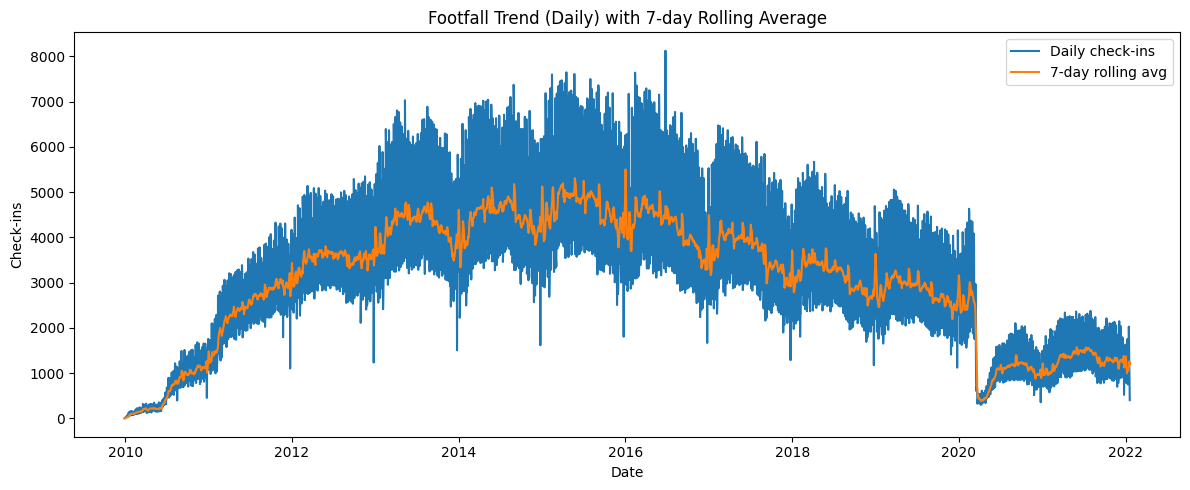

In [14]:
import matplotlib.pyplot as plt

print("\n---------- CHART 01: Daily Trend + Rolling Avg ----------")

print("\nDescriptive Measures: checkins")
numeric_desc_table(df_C7_daily_cleaned, "checkins").show(truncate=False)

print("\nDescriptive Measures: checkins_7d_avg")
numeric_desc_table(df_C7_daily_cleaned, "checkins_7d_avg").show(truncate=False)

print("\nSupporting Table (last 15 days)")
df_C7_daily_cleaned.orderBy(F.desc("checkin_date")).limit(15).show(truncate=False)

pdf_daily = df_C7_daily_cleaned.orderBy("checkin_date").toPandas()

plt.figure(figsize=(12,5))
plt.plot(pdf_daily["checkin_date"], pdf_daily["checkins"], label="Daily check-ins")
plt.plot(pdf_daily["checkin_date"], pdf_daily["checkins_7d_avg"], label="7-day rolling avg")
plt.title("Footfall Trend (Daily) with 7-day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Check-ins")
plt.legend()
plt.tight_layout()
plt.show()


###Chart 02 - Weekday × Hour Heatmap


---------- CHART 02: Weekday × Hour Heatmap ----------

Supporting Frequency Table (Top 25 cells)
+---+----+------+
|dow|hour|cnt   |
+---+----+------+
|7  |23  |228906|
|7  |18  |226016|
|1  |0   |222567|
|7  |0   |221581|
|7  |17  |215954|
|6  |23  |215107|
|7  |19  |214644|
|7  |22  |212631|
|1  |18  |199909|
|7  |20  |199815|
|1  |17  |198292|
|7  |21  |197667|
|7  |1   |191718|
|1  |1   |191507|
|1  |19  |184543|
|7  |16  |180448|
|6  |22  |177891|
|5  |23  |166274|
|1  |16  |166209|
|1  |20  |165877|
+---+----+------+
only showing top 20 rows

Descriptive Measures: Hour of Day (0–23)
+----+----+------------------+------+---+----------------+----------+--------+---+----+-----+-----------------+-----------------+--------+-----------------+
|IQR |max |mean              |median|min|mode_bin_start_1|mode_count|n       |q1 |q3  |range|skewness         |stddev           |variable|variance         |
+----+----+------------------+------+---+----------------+----------+--------+---+----+-

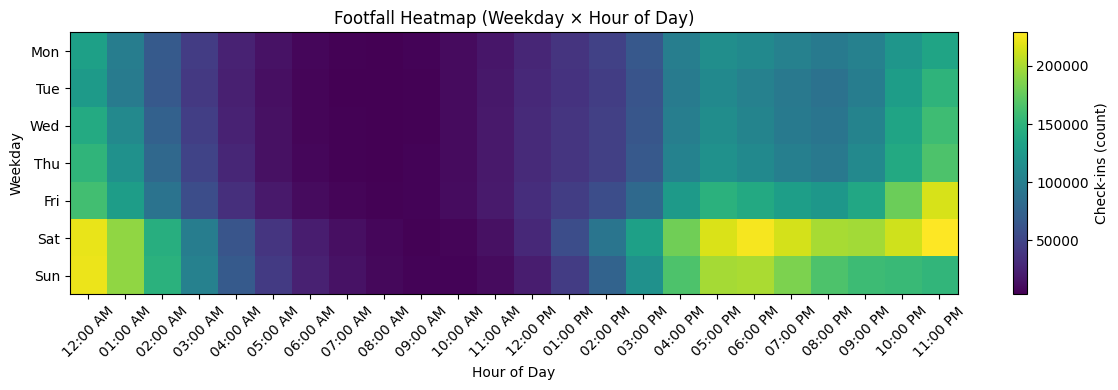

In [15]:
import numpy as np

import numpy as np
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

print("\n---------- CHART 02: Weekday × Hour Heatmap ----------")
df_heat = (
    df_C6_events_cleaned
    .groupBy("dow", "hour")
    .agg(F.count("*").alias("cnt"))
    .orderBy(F.desc("cnt"))
)

print("\nSupporting Frequency Table (Top 25 cells)")
df_heat.limit(25).show(truncate=False)

print("\nDescriptive Measures: Hour of Day (0–23)")
numeric_desc_table(df_C6_events_cleaned, "hour", mode_bin=1).show(truncate=False)
pdf_heat = df_heat.toPandas()

dow_map = {
    1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed",
    5: "Thu", 6: "Fri", 7: "Sat"
}
pdf_heat["dow_name"] = pdf_heat["dow"].map(dow_map)

mat = (
    pdf_heat
    .pivot_table(
        index="dow_name",
        columns="hour",
        values="cnt",
        aggfunc="sum",
        fill_value=0
    )
    .reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
)

hour_labels = [
    f"{(h % 12 or 12):02d}:00 {'AM' if h < 12 else 'PM'}"
    for h in mat.columns
]

plt.figure(figsize=(12, 4))
plt.imshow(mat.values, aspect="auto")
plt.title("Footfall Heatmap (Weekday × Hour of Day)")
plt.xlabel("Hour of Day")
plt.ylabel("Weekday")
plt.xticks(ticks=np.arange(len(mat.columns)), labels=hour_labels, rotation=45)
plt.yticks(ticks=np.arange(len(mat.index)), labels=mat.index)
plt.colorbar(label="Check-ins (count)")
plt.tight_layout()
plt.show()

###Chart 03 - Bar: Top 10 Businesses by Total Check-ins


---------- CHART 03: Top 10 Businesses ----------

Supporting Table: Top 10 businesses
+----------------------+--------+
|business_id           |checkins|
+----------------------+--------+
|-QI8Qi8XWH3D8y8ethnajA|52144   |
|FEXhWNCMkv22qG04E83Qjg|40109   |
|Eb1XmmLWyt_way5NNZ7-Pw|37562   |
|c_4c5rJECZSfNgFj7frwHQ|37518   |
|4i4kmYm9wgSNyF1b6gKphg|31168   |
|8O35ji_yOMVJmZ6bl96yhQ|29606   |
|VQcCL9PiNL_wkGf-uF3fjg|28927   |
|ac1AeYqs8Z4_e2X5M3if2A|21542   |
|QTbahs-GVuWYL5yfdjH34A|21487   |
|ytynqOUb3hjKeJfRj5Tshw|18615   |
+----------------------+--------+



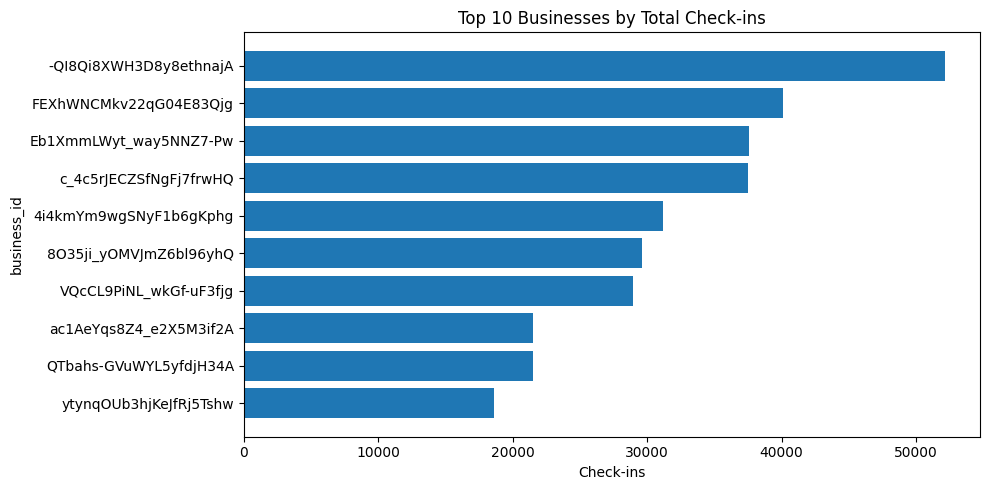

In [16]:
print("\n---------- CHART 03: Top 10 Businesses ----------")

df_top10 = (df_C6_events_cleaned
            .groupBy("business_id")
            .agg(F.count("*").alias("checkins"))
            .orderBy(F.desc("checkins"))
            .limit(10))

print("\nSupporting Table: Top 10 businesses")
df_top10.show(truncate=False)

pdf_top10 = df_top10.toPandas()

plt.figure(figsize=(10,5))
plt.barh(pdf_top10["business_id"], pdf_top10["checkins"])
plt.gca().invert_yaxis()
plt.title("Top 10 Businesses by Total Check-ins")
plt.xlabel("Check-ins")
plt.ylabel("business_id")
plt.tight_layout()
plt.show()


###Chart 04 - Boxplot: Daily Check-ins Distribution by Month


---------- CHART 04: Boxplot (Daily Check-ins by Month) ----------

Supporting Table: Monthly summary
+-----+----+------------------+---------------+------------+------------+
|month|days|mean_checkins     |median_checkins|min_checkins|max_checkins|
+-----+----+------------------+---------------+------------+------------+
|1    |376 |2808.2393617021276|2749           |58          |7185        |
|2    |339 |3061.873156342183 |3041           |77          |7637        |
|3    |372 |3164.1881720430106|3222           |107         |7470        |
|4    |360 |3089.4555555555557|3210           |117         |7647        |
|5    |372 |3155.8682795698924|3203           |146         |7608        |
|6    |360 |3125.8555555555554|3268           |157         |8123        |
|7    |372 |3189.19623655914  |3278           |432         |7071        |
|8    |372 |3149.9274193548385|3065           |396         |7498        |
|9    |360 |3014.113888888889 |2950           |689         |7360        |
|10   |37

/tmp/ipython-input-2774995962.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=True)


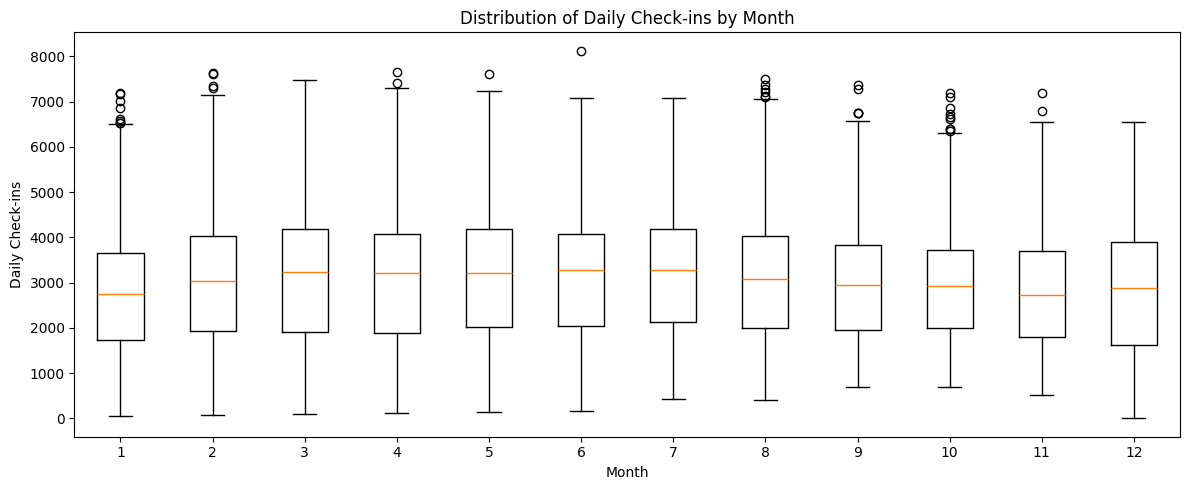

In [17]:
print("\n---------- CHART 04: Boxplot (Daily Check-ins by Month) ----------")

df_month_summary = (df_C7_daily_cleaned
    .groupBy("month")
    .agg(
        F.count("*").alias("days"),
        F.mean("checkins").alias("mean_checkins"),
        F.expr("percentile_approx(checkins, 0.5)").alias("median_checkins"),
        F.min("checkins").alias("min_checkins"),
        F.max("checkins").alias("max_checkins")
    )
    .orderBy("month"))

print("\nSupporting Table: Monthly summary")
df_month_summary.show(12, truncate=False)

pdf_box = df_C7_daily_cleaned.select("month", "checkins").toPandas()
months = sorted(pdf_box["month"].dropna().unique())
data = [pdf_box.loc[pdf_box["month"] == m, "checkins"].values for m in months]
labels = [str(m) for m in months]

plt.figure(figsize=(12,5))
plt.boxplot(data, labels=labels, showfliers=True)
plt.title("Distribution of Daily Check-ins by Month")
plt.xlabel("Month")
plt.ylabel("Daily Check-ins")
plt.tight_layout()
plt.show()


###Chart 05 - Daily Check-ins by Day-of-Week


---------- CHART 05: Daily Check-ins by Day-of-Week (Table + Boxplot) ----------

Supporting Table: Day-of-week summary
+-----------+----+------------------+---------------+------------+------------+
|day_of_week|days|mean_checkins     |median_checkins|min_checkins|max_checkins|
+-----------+----+------------------+---------------+------------+------------+
|1          |627 |3956.4609250398726|4325           |135         |7273        |
|2          |627 |2379.5741626794256|2529           |69          |5699        |
|3          |627 |2329.237639553429 |2509           |58          |5246        |
|4          |628 |2455.046178343949 |2647           |1           |5467        |
|5          |627 |2571.7639553429026|2768           |1           |5668        |
|6          |626 |3129.4169329073484|3425           |73          |6662        |
|7          |627 |4482.406698564593 |4860           |100         |8123        |
+-----------+----+------------------+---------------+------------+------------+

/tmp/ipython-input-2045281745.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=True)


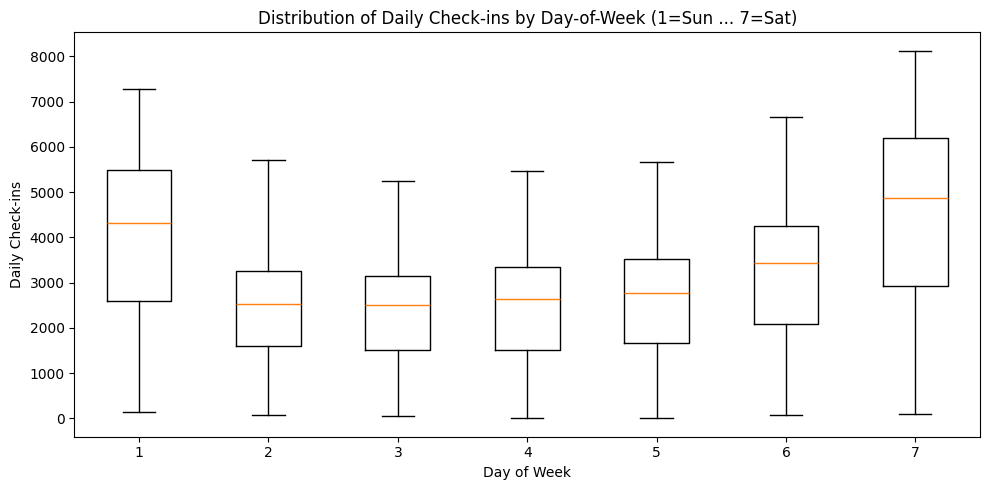

In [18]:
print("\n---------- CHART 05 - Boxplot: Daily Check-ins by Day-of-Week ----------")

df_dow_summary = (df_C7_daily_cleaned
    .groupBy("day_of_week")
    .agg(
        F.count("*").alias("days"),
        F.mean("checkins").alias("mean_checkins"),
        F.expr("percentile_approx(checkins, 0.5)").alias("median_checkins"),
        F.min("checkins").alias("min_checkins"),
        F.max("checkins").alias("max_checkins")
    )
    .orderBy("day_of_week"))

print("\nSupporting Table: Day-of-week summary")
df_dow_summary.show(truncate=False)

pdf_dow = df_C7_daily_cleaned.select("day_of_week", "checkins").toPandas()
dows = sorted(pdf_dow["day_of_week"].dropna().unique())
data = [pdf_dow.loc[pdf_dow["day_of_week"] == d, "checkins"].values for d in dows]
labels = [str(d) for d in dows]

plt.figure(figsize=(10,5))
plt.boxplot(data, labels=labels, showfliers=True)
plt.title("Distribution of Daily Check-ins by Day-of-Week (1=Sun ... 7=Sat)")
plt.xlabel("Day of Week")
plt.ylabel("Daily Check-ins")
plt.tight_layout()
plt.show()


#Data Analysis for Dashboard 03

##KPI Table

In [19]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

print("\n---------Dashboard KPI----------\n")

dfC = (df_C7_daily_cleaned
       .withColumn("checkin_date", F.to_date("checkin_date"))
       .withColumn("checkins", F.col("checkins").cast("double"))
       .withColumn("month", F.col("month").cast("int"))
       .withColumn("high_traffic", F.col("high_traffic").cast("int"))
)

# KPI 1: High-Traffic Day Share (%)
kpi_high_traffic_share = (dfC
    .where(F.col("high_traffic").isNotNull())
    .agg(F.avg("high_traffic").alias("share"))
    .collect()[0]["share"]
)

kpi_checkins = spark.createDataFrame([
    ("High-Traffic Day Share (%)", float(kpi_high_traffic_share) if kpi_high_traffic_share is not None else None),
], ["KPI", "Value"])

kpi_checkins.show(truncate=False)



---------Dashboard KPI----------

+--------------------------+------------------+
|KPI                       |Value             |
+--------------------------+------------------+
|High-Traffic Day Share (%)|0.2579175210754158|
+--------------------------+------------------+



##Chart 01- Line: Weekly Check-ins + 4-Week Average


---------- CHART 01: Weekly Total Check-ins (Trend) ----------

Supporting Table (last 15 weeks)
+----------+---------------+
|week_start|weekly_checkins|
+----------+---------------+
|2022-01-17|2638.0         |
|2022-01-10|8105.0         |
|2022-01-03|7592.0         |
|2021-12-27|9585.0         |
|2021-12-20|7852.0         |
|2021-12-13|8662.0         |
|2021-12-06|8889.0         |
|2021-11-29|8579.0         |
|2021-11-22|8482.0         |
|2021-11-15|8897.0         |
|2021-11-08|9240.0         |
|2021-11-01|8762.0         |
|2021-10-25|8968.0         |
|2021-10-18|9207.0         |
|2021-10-11|9025.0         |
+----------+---------------+


Descriptive Measures: weekly_checkins
+-------+-------+------------------+-------+---+----------+----------+---+-------+-------+-------+-------------------+-----------------+---------------+-------------------+
|IQR    |max    |mean              |median |min|mode_count|mode_exact|n  |q1     |q3     |range  |skewness           |stddev           |va

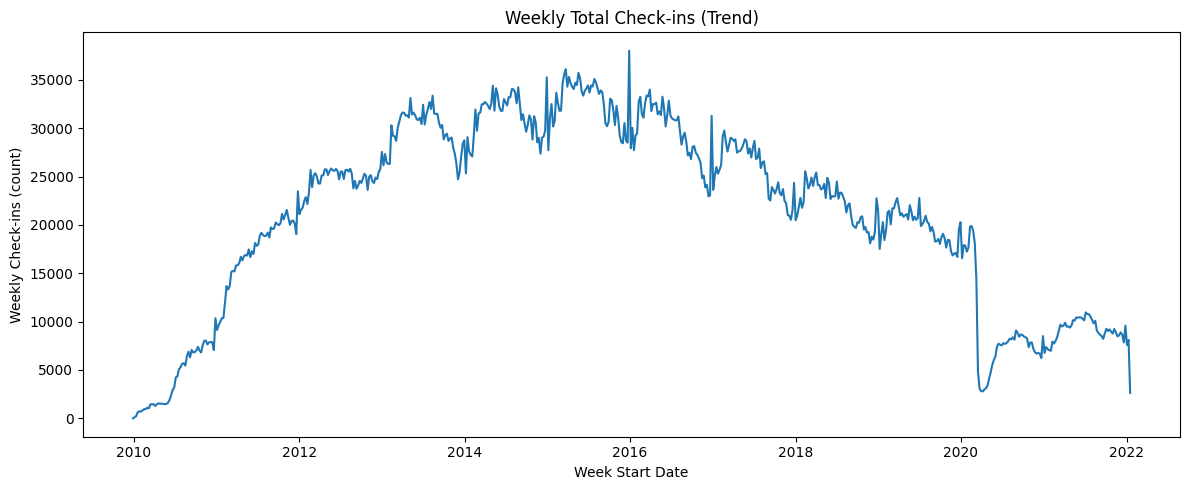

In [20]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

print("\n---------- CHART 01: Weekly Total Check-ins (Trend) ----------")

df_weekly = (df_C7_daily_cleaned
    .withColumn("checkin_date", F.to_date("checkin_date"))
    .withColumn("checkins", F.col("checkins").cast("double"))
    .where(F.col("checkin_date").isNotNull() & F.col("checkins").isNotNull())
    .withColumn("week_start", F.date_trunc("week", F.col("checkin_date")).cast("date"))
    .groupBy("week_start")
    .agg(F.sum("checkins").alias("weekly_checkins"))
    .orderBy("week_start")
)

print("\nSupporting Table (last 15 weeks)")
df_weekly.orderBy(F.desc("week_start")).limit(15).show(truncate=False)

print("\nDescriptive Measures: weekly_checkins")
numeric_desc_table(df_weekly.where(F.col("weekly_checkins").isNotNull()), "weekly_checkins").show(truncate=False)

pdf_week = df_weekly.toPandas()

plt.figure(figsize=(12,5))
plt.plot(pdf_week["week_start"], pdf_week["weekly_checkins"])
plt.title("Weekly Total Check-ins (Trend)")
plt.xlabel("Week Start Date")
plt.ylabel("Weekly Check-ins (count)")
plt.tight_layout()
plt.show()


##Chart 02- Bar:High-Traffic Day Share by Month


---------- CHART 02: High-Traffic Days by Month (%) ----------

Supporting Table: High-traffic share by month
+-----+----+-------------------+
|month|days|high_traffic_share |
+-----+----+-------------------+
|1    |376 |0.19946808510638298|
|2    |339 |0.25958702064896755|
|3    |372 |0.2956989247311828 |
|4    |360 |0.2777777777777778 |
|5    |372 |0.3010752688172043 |
|6    |360 |0.2916666666666667 |
|7    |372 |0.30376344086021506|
|8    |372 |0.26881720430107525|
|9    |360 |0.23055555555555557|
|10   |372 |0.21774193548387097|
|11   |360 |0.21388888888888888|
|12   |374 |0.23529411764705882|
+-----+----+-------------------+


Descriptive Measures: high_traffic_share
+-------------------+-------------------+------------------+-------------------+-------------------+----------+-------------------+---+-------------------+------------------+-------------------+--------------------+--------------------+------------------+---------------------+
|IQR                |max                

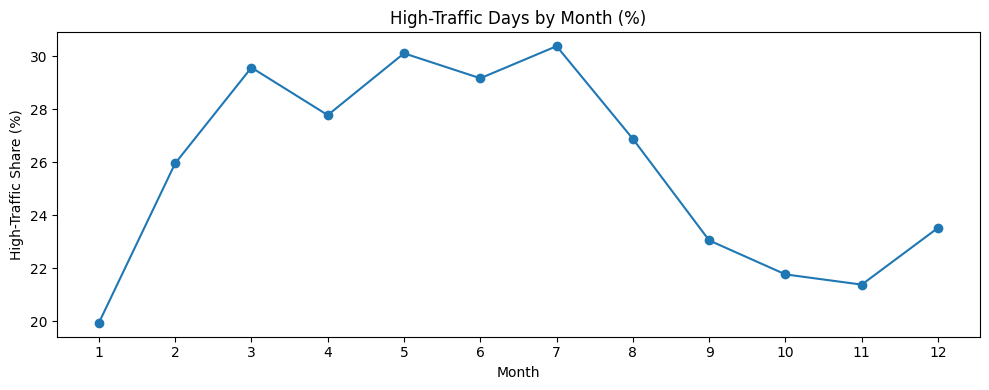

In [21]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt
import numpy as np

print("\n---------- CHART 02: High-Traffic Days by Month (%) ----------")

df_ht_month = (df_C7_daily_cleaned
    .withColumn("month", F.col("month").cast("int"))
    .withColumn("high_traffic", F.col("high_traffic").cast("int"))
    .where(F.col("month").isNotNull() & F.col("high_traffic").isNotNull())
    .groupBy("month")
    .agg(
        F.count("*").alias("days"),
        F.avg("high_traffic").alias("high_traffic_share")  # 0..1
    )
    .orderBy("month")
)

print("\nSupporting Table: High-traffic share by month")
df_ht_month.show(12, truncate=False)

print("\nDescriptive Measures: high_traffic_share")
numeric_desc_table(df_ht_month.where(F.col("high_traffic_share").isNotNull()), "high_traffic_share").show(truncate=False)

pdf_ht = df_ht_month.toPandas()

plt.figure(figsize=(10,4))
plt.plot(pdf_ht["month"], pdf_ht["high_traffic_share"] * 100.0, marker="o")
plt.xticks(ticks=np.arange(1,13), labels=[str(i) for i in range(1,13)])
plt.title("High-Traffic Days by Month (%)")
plt.xlabel("Month")
plt.ylabel("High-Traffic Share (%)")
plt.tight_layout()
plt.show()


##Chart 03:Scatter: Check-ins vs Lag-7


---------- CHART 03: Check-ins vs Lag-7 ----------

Descriptive Measures: Check-ins
+------+------+-----------------+------+---+----------+----------+----+------+------+------+-------------------+------------------+--------+----------------+
|IQR   |max   |mean             |median|min|mode_count|mode_exact|n   |q1    |q3    |range |skewness           |stddev            |variable|variance        |
+------+------+-----------------+------+---+----------+----------+----+------+------+------+-------------------+------------------+--------+----------------+
|2112.0|8123.0|3043.261562998405|3013.0|1.0|6         |2875      |4389|1839.0|3951.0|8122.0|0.32822245991123716|1641.3288105357897|checkins|2693960.26429483|
+------+------+-----------------+------+---+----------+----------+----+------+------+------+-------------------+------------------+--------+----------------+


Descriptive Measures: Lag-7 Check-ins
+------+------+------------------+------+---+----------+----------+----+------+------

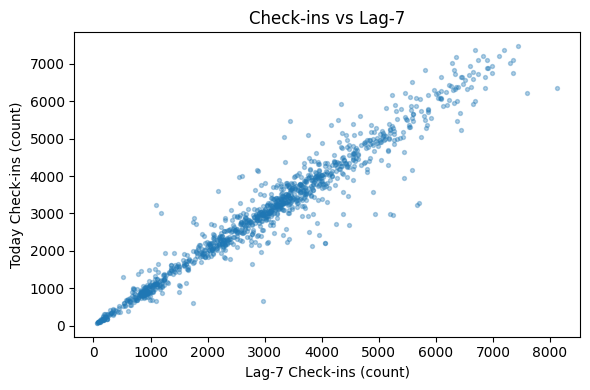

In [22]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

print("\n---------- CHART 03: Check-ins vs Lag-7 ----------")

print("\nDescriptive Measures: Check-ins")
numeric_desc_table(
    df_C7_daily_cleaned.where(F.col("checkins").isNotNull()),
    "checkins"
).show(truncate=False)

print("\nDescriptive Measures: Lag-7 Check-ins")
numeric_desc_table(
    df_C7_daily_cleaned.where(F.col("lag_7").isNotNull()),
    "lag_7"
).show(truncate=False)

df_lag_clean = (
    df_C7_daily_cleaned
    .select(
        F.col("lag_7").cast("double").alias("lag_7"),
        F.col("checkins").cast("double").alias("checkins")
    )
    .where(F.col("lag_7").isNotNull() & F.col("checkins").isNotNull())
)

print("\nSupporting Table (sample 20 rows)")
df_lag_clean.limit(20).show(truncate=False)

corr_val = df_lag_clean.stat.corr("lag_7", "checkins")
cov_val  = df_lag_clean.stat.cov("lag_7", "checkins")

rel_table = spark.createDataFrame([
    ("Correlation (Lag-7 vs Check-ins)", float(corr_val) if corr_val is not None else None),
    ("Covariance (Lag-7 vs Check-ins)", float(cov_val) if cov_val is not None else None)
], ["Measure", "Value"])

print("\nRelationship Measures (Check-ins vs Lag-7)")
rel_table.show(truncate=False)

lag_pd = df_lag_clean.sample(False, 0.25, seed=7).toPandas()

plt.figure(figsize=(6,4))
plt.scatter(lag_pd["lag_7"], lag_pd["checkins"], s=8, alpha=0.35)
plt.title("Check-ins vs Lag-7")
plt.xlabel("Lag-7 Check-ins (count)")
plt.ylabel("Today Check-ins (count)")
plt.tight_layout()
plt.show()
